# plot_erosion_compare.py

*Generated from `plot_erosion_compare.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
plot_erosion_compare.py - overlays SURFACES at one energy (plot_erosion_energies.py
overlays energies) and writes an equal-fluence summary table.

Outputs (OUT_DIR):
    surface_W_pct_<E>eV.png    near-surface W at.% vs fluence, WC surfaces
    W001_surface_He.png        near-surface He at.% vs fluence, W(001), all energies
    he_retention_<E>eV.png     retained / implanted He vs fluence (he_retained column)
    he_clusters_<E>eV.png      He clusters of 2-3, 4-6, 7+ He vs fluence, per surface
    erosion_summary_equal_fluence.csv
        C and W removed, R_D, growth, surface W at.%, He retained and clusters
        at COMPARE_CYCLE for every run, plus the yield over the first and last
        BLOCK cycles.

    python plot_erosion_compare.py [--dir CSVs] [--out figs] [--energy 200]
                                   [--compare-cycle 1000] [--energies 50 100 200]

Requires numpy, pandas, matplotlib.
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'plot_erosion_compare.py'
NB_CSV = "."          # the same CSVs as plot_erosion_energies.py
NB_OUT = "nb_figs"
os.makedirs(NB_OUT, exist_ok=True)
ARGS = ["--dir", NB_CSV, "--out", NB_OUT, "--energy", "100"]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse
import os
import sys

import numpy as np
import pandas as pd
import matplotlib

if "--show" not in sys.argv:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

In [3]:
# ===========================================================================
# SETTINGS
# ===========================================================================
CSV_DIR = "."
OUT_DIR = "."
ENERGY = 100                         # eV, for the overlay figures
ENERGIES = [50, 100, 200]            # for the summary table

SURFACES = {                          # key: (file template, label, color)
    "bC": ("erosion_WC_basal_C_{E}eV.csv", "WC basal, C-terminated", "#e2711d"),
    "bW": ("erosion_WC_basal_W_{E}eV.csv", "WC basal, W-terminated", "#4b4b4b"),
    "pr": ("erosion_WC_prism_{E}eV.csv", "WC prism", "#2b7bba"),
}
W001_FILE = "erosion_W001_{E}eV.csv"
W001_LABEL, W001_COLOR = "W(001)", "#6a3d9a"
HE_BIN_COLS = [("he_clusters_2_3", "2–3 He"), ("he_clusters_4_6", "4–6 He"),
               ("he_clusters_7plus", "7+ He")]
HE_BIN_COLORS = ["#e9a03b", "#d9480f", "#7d0a12"]
CLUSTER_COLS = None                  # None = one row; 2 = 2x2 grid (--cluster-cols)
RETENTION_SKIP = 20                  # first cycles hidden on the retention plot (1/N noise)

# Impact area (A^2) = central 2/3 x 2/3 of the cell (W(001) is an estimate).
IMPACT_AREA_A2 = {"bC": 3567.0, "bW": 3567.0, "pr": 3420.0, "W001": 3490.0}

COMPARE_CYCLE = 1200                 # equal-fluence comparison point
BLOCK = 375                          # cycles in the early / late yield blocks
SMOOTH = 25                          # rolling mean (cycles) for at.% curves
RAW_ALPHA = 0.18

FIG_SIZE = (7.2, 4.6)
FIG_DPI = 200
TITLE_KW = dict(fontsize=13)
LABEL_KW = dict(fontsize=11.5)
TICK_KW = dict(labelsize=10)
GRID_KW = dict(color="#b8b8b8", linestyle=":", linewidth=0.8, alpha=0.7)
LEGEND_KW = dict(frameon=True, framealpha=0.9, fontsize=9)
FLUENCE_EXP = 19
X_LABEL = r"Fluence ($10^{%d}$ He m$^{-2}$)" % FLUENCE_EXP

In [4]:
# ===========================================================================


def fluence(cycles, area_A2):
    return np.asarray(cycles, float) / (area_A2 * 1e-20) / 10.0 ** FLUENCE_EXP


def roll(y, w):
    return pd.Series(y).rolling(w, center=True, min_periods=1).mean().values


def style(ax, ylabel, title):
    ax.set_xlabel(X_LABEL, **LABEL_KW)
    ax.set_ylabel(ylabel, **LABEL_KW)
    ax.tick_params(**TICK_KW)
    ax.grid(True, **GRID_KW)
    ax.set_axisbelow(True)
    ax.set_title(title, **TITLE_KW)


def save(fig, out_dir, name):
    fig.tight_layout()
    path = os.path.join(out_dir, name)
    fig.savefig(path, dpi=FIG_DPI)
    plt.close(fig)
    print("  wrote", path)


def surface_w_figure(csv_dir, out_dir, E):
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for key, (tmpl, label, color) in SURFACES.items():
        path = os.path.join(csv_dir, tmpl.format(E=E))
        if not os.path.isfile(path):
            print("  missing", path)
            continue
        d = pd.read_csv(path)
        x = fluence(d["cycle"], IMPACT_AREA_A2[key])
        y = d["surface_W_at_pct"].values
        ax.plot(x, y, color=color, alpha=RAW_ALPHA, linewidth=0.8)
        ax.plot(x, roll(y, SMOOTH), color=color, linewidth=1.6, label=label)
    ax.axhline(50.0, color="#7f7f7f", linewidth=0.9, linestyle="--")
    ax.text(0.99, 50.0, "stoichiometric WC ", color="#7f7f7f", fontsize=9,
            va="top", ha="right", transform=ax.get_yaxis_transform())
    style(ax, "Near-surface W (at.%)", "Near-surface W content - %g eV He" % E)
    ax.legend(loc="upper left", **LEGEND_KW)
    save(fig, out_dir, "surface_W_pct_%geV.png" % E)

In [5]:
def w001_he_figure(csv_dir, out_dir, E):
    """Near-surface He at.% in W(001), every available energy overlaid."""
    found = []
    for Ei in ENERGIES:
        path = os.path.join(csv_dir, W001_FILE.format(E=Ei))
        if os.path.isfile(path):
            found.append((Ei, pd.read_csv(path)))
    if not found:
        print("  missing", os.path.join(csv_dir, W001_FILE.format(E=E)))
        return
    shades = ["#b39ddb", "#6a3d9a", "#3f007d"]
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for i, (Ei, d) in enumerate(found):
        c = shades[min(i + (3 - len(found)), 2)] if len(found) < 3 else shades[i]
        x = fluence(d["cycle"], IMPACT_AREA_A2["W001"])
        y = d["surface_He_at_pct"].values
        ax.plot(x, y, color=c, alpha=RAW_ALPHA, linewidth=0.8)
        ax.plot(x, roll(y, SMOOTH), color=c, linewidth=1.6, label="%g eV" % Ei)
    style(ax, "Near-surface He (at.%)", "Near-surface He content - W(001)")
    ax.legend(loc="upper left", **LEGEND_KW)
    name = "W001_surface_He.png" if len(found) > 1 else "W001_surface_He_%geV.png" % found[0][0]
    save(fig, out_dir, name)


def all_runs(csv_dir, E):
    """(key, label, color, area, DataFrame) for every surface found at E."""
    out = []
    for key, (tmpl, label, color) in SURFACES.items():
        path = os.path.join(csv_dir, tmpl.format(E=E))
        if os.path.isfile(path):
            out.append((key, label, color, IMPACT_AREA_A2[key], pd.read_csv(path)))
    path = os.path.join(csv_dir, W001_FILE.format(E=E))
    if os.path.isfile(path):
        out.append(("W001", W001_LABEL, W001_COLOR, IMPACT_AREA_A2["W001"],
                    pd.read_csv(path)))
    return out


def he_retention_figure(csv_dir, out_dir, E):
    runs = [r for r in all_runs(csv_dir, E) if "he_retained" in r[4]]
    if not runs:
        print("  no he_retained column at %g eV - he_retention figure skipped" % E)
        return
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for key, label, color, area, d in runs:
        d = d[d["cycle"] > RETENTION_SKIP]
        x = fluence(d["cycle"], area)
        y = 100.0 * d["he_retained"].values / d["cycle"].values
        ax.plot(x, y, color=color, linewidth=1.6, label=label)
    ax.set_ylim(0, 100)
    style(ax, "He retained / He implanted (%)", "He retention - %g eV He" % E)
    ax.legend(loc="upper right", **LEGEND_KW)
    save(fig, out_dir, "he_retention_%geV.png" % E)

In [6]:
def he_cluster_figure(csv_dir, out_dir, E):
    runs = [r for r in all_runs(csv_dir, E) if "he_clusters_7plus" in r[4]]
    if not runs:
        print("  no He cluster columns at %g eV - he_clusters figure skipped" % E)
        return
    n = len(runs)
    ncol = CLUSTER_COLS or n
    nrow = int(np.ceil(n / ncol))
    if CLUSTER_COLS:
        size = FIG_SIZE
    else:
        size = (FIG_SIZE[0] * n / 2.2, FIG_SIZE[1] * 0.85)
    fig, axs = plt.subplots(nrow, ncol, figsize=size, sharey=True, squeeze=False)
    flat = axs.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)
    ymax = 0
    for k, (ax, (key, label, color, area, d)) in enumerate(zip(flat, runs)):
        x = fluence(d["cycle"], area)
        for (col, lab), c in zip(HE_BIN_COLS, HE_BIN_COLORS):
            y = d[col].values
            ax.plot(x, y, color=c, alpha=RAW_ALPHA, linewidth=0.8)
            ys = roll(y, SMOOTH)
            ax.plot(x, ys, color=c, linewidth=1.7, label=lab)
            ymax = max(ymax, float(np.nanmax(y)))
        ax.set_title(label, fontsize=12 if not CLUSTER_COLS else 10)
        if k // ncol == nrow - 1 or not CLUSTER_COLS:
            ax.set_xlabel(X_LABEL, **LABEL_KW)
        ax.tick_params(**TICK_KW)
        ax.grid(True, **GRID_KW)
        ax.set_axisbelow(True)
    for r in range(nrow):
        axs[r][0].set_ylabel("He clusters", **LABEL_KW)
    axs[0][0].set_ylim(0, ymax * 1.08 + 1)
    # legend in the last panel (W(001) has little in its upper left)
    flat[n - 1].legend(loc="upper left", title="Cluster size", **LEGEND_KW)
    fig.suptitle("He clusters in the whole cell - %g eV He (cutoff 2.5 Å)" % E,
                 **TITLE_KW)
    save(fig, out_dir, ("he_clusters_%geV.png" if not CLUSTER_COLS
                        else "he_clusters_%geV_grid.png") % E)

In [7]:
def _yield_block(d, col, lo, hi):
    """Atoms of `col` removed per He over cycles lo+1 .. hi."""
    a = d.loc[lo, col] if lo > 0 else 0
    return (d.loc[hi, col] - a) / (hi - lo)


def summary_table(csv_dir, out_dir):
    rows = []
    for E in ENERGIES:
        for key, label, _, area, d in all_runs(csv_dir, E):
            d = d.set_index("cycle")
            n = int(d.index.max())
            sp = "sputtered_W" if key == "W001" else "sputtered_C"
            at = d.loc[COMPARE_CYCLE] if n >= COMPARE_CYCLE else None
            early = _yield_block(d, sp, 0, min(BLOCK, n))
            late = _yield_block(d, sp, n - BLOCK, n) if n >= 2 * BLOCK else np.nan
            row = dict(
                surface=label, energy_eV=E, cycles=n,
                fluence_end_1e19=round(float(fluence(n, area)), 3),
                compare_cycle=COMPARE_CYCLE,
                fluence_compare_1e19=round(float(fluence(COMPARE_CYCLE, area)), 3),
                C_removed_total=int(d.loc[n, "sputtered_C"]),
                W_removed_total=int(d.loc[n, "sputtered_W"]),
                C_at_compare=None if at is None else int(at["sputtered_C"]),
                W_at_compare=None if at is None else int(at["sputtered_W"]),
                C_yield_to_compare=None if at is None
                else round(at["sputtered_C"] / COMPARE_CYCLE, 4),
                W_yield_to_compare=None if at is None
                else round(at["sputtered_W"] / COMPARE_CYCLE, 5),
                main_species=sp.split("_")[1],
                yield_first_block=round(early, 4),
                yield_last_block=round(late, 4),
                order_deficit_A_at_compare=None if at is None
                else round(at["order_deficit_A"], 3),
                growth_A_at_compare=None if at is None
                else round(at["growth_A"], 3),
                z_surf_change_A_at_compare=None if at is None
                else round(at["z_surf_A"] - d["z_surf_A"].iloc[0], 3),
            )
            if "surface_W_at_pct" in d:
                row.update(surface_W_pct_start=round(d["surface_W_at_pct"].iloc[:20].mean(), 2),
                           surface_W_pct_end=round(d["surface_W_at_pct"].iloc[-20:].mean(), 2),
                           surface_W_pct_at_compare=None if at is None else round(
                               d["surface_W_at_pct"].loc[COMPARE_CYCLE - SMOOTH:COMPARE_CYCLE + SMOOTH].mean(), 2))
            if "he_retained" in d and at is not None:
                row.update(he_retained_at_compare=int(at["he_retained"]),
                           he_retained_pct_at_compare=round(100.0 * at["he_retained"] / COMPARE_CYCLE, 1),
                           he_isolated_at_compare=int(at["he_isolated"]),
                           he_clusters_2_3_at_compare=int(at["he_clusters_2_3"]),
                           he_clusters_4_6_at_compare=int(at["he_clusters_4_6"]),
                           he_clusters_7plus_at_compare=int(at["he_clusters_7plus"]))
            if "he_retained" in d:
                row.update(he_retained_end=int(d.loc[n, "he_retained"]),
                           he_retained_pct_end=round(100.0 * d.loc[n, "he_retained"] / n, 1),
                           he_clusters_7plus_end=int(d.loc[n, "he_clusters_7plus"]))
            rows.append(row)
    df = pd.DataFrame(rows)
    path = os.path.join(out_dir, "erosion_summary_equal_fluence.csv")
    df.to_csv(path, index=False)
    print("  wrote", path)
    with pd.option_context("display.width", 250, "display.max_columns", 40):
        print(df.to_string(index=False))
    return df

In [8]:
def main():
    global FIG_SIZE, COMPARE_CYCLE, ENERGIES, CLUSTER_COLS
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dir", default=CSV_DIR)
    ap.add_argument("--out", default=OUT_DIR)
    ap.add_argument("--energy", type=float, default=ENERGY)
    ap.add_argument("--energies", nargs="+", type=int, default=None,
                    help="energies for the summary table")
    ap.add_argument("--compare-cycle", type=int, default=None,
                    help="equal-fluence comparison cycle (default %d)" % COMPARE_CYCLE)
    ap.add_argument("--figsize", nargs=2, type=float, default=None, metavar=("W", "H"))
    ap.add_argument("--no-table", action="store_true", help="figures only")
    ap.add_argument("--cluster-cols", type=int, default=None,
                    help="panels per row on the He-cluster figure (2 = 2x2 grid)")
    ap.add_argument("--show", action="store_true")
    a = ap.parse_args()
    if a.figsize:
        FIG_SIZE = tuple(a.figsize)
    if a.cluster_cols:
        CLUSTER_COLS = a.cluster_cols
    if a.compare_cycle:
        COMPARE_CYCLE = a.compare_cycle
    if a.energies:
        ENERGIES = a.energies
    os.makedirs(a.out, exist_ok=True)
    E = int(a.energy) if float(a.energy).is_integer() else a.energy
    surface_w_figure(a.dir, a.out, E)
    w001_he_figure(a.dir, a.out, E)
    he_retention_figure(a.dir, a.out, E)
    he_cluster_figure(a.dir, a.out, E)
    if not a.no_table:
        summary_table(a.dir, a.out)

In [9]:
if __name__ == "__main__":
    main()

  wrote nb_figs/surface_W_pct_100eV.png


  wrote nb_figs/W001_surface_He.png


  wrote nb_figs/he_retention_100eV.png


  wrote nb_figs/he_clusters_100eV.png
  wrote nb_figs/erosion_summary_equal_fluence.csv
               surface  energy_eV  cycles  fluence_end_1e19  compare_cycle  fluence_compare_1e19  C_removed_total  W_removed_total  C_at_compare  W_at_compare  C_yield_to_compare  W_yield_to_compare main_species  yield_first_block  yield_last_block  order_deficit_A_at_compare  growth_A_at_compare  z_surf_change_A_at_compare  surface_W_pct_start  surface_W_pct_end  surface_W_pct_at_compare  he_retained_at_compare  he_retained_pct_at_compare  he_isolated_at_compare  he_clusters_2_3_at_compare  he_clusters_4_6_at_compare  he_clusters_7plus_at_compare  he_retained_end  he_retained_pct_end  he_clusters_7plus_end
WC basal, C-terminated         50    1564             4.385           1200                 3.364              182                0           130             0              0.1083             0.00000            C             0.1547            0.1387                      -2.931                2.628

## Outputs

In [10]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


surface_W_pct_100eV.png


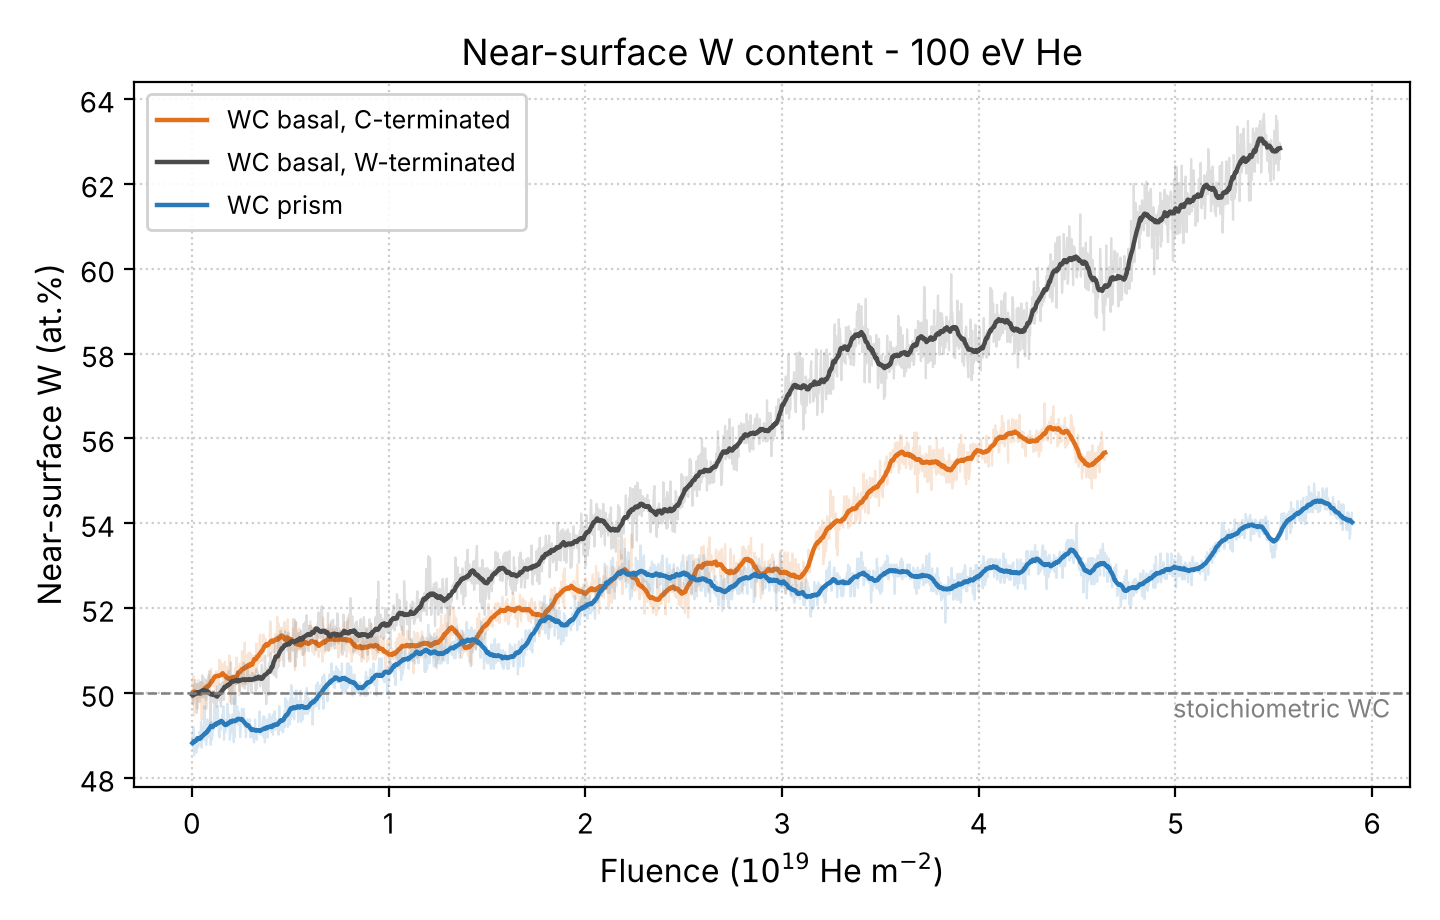

he_retention_100eV.png


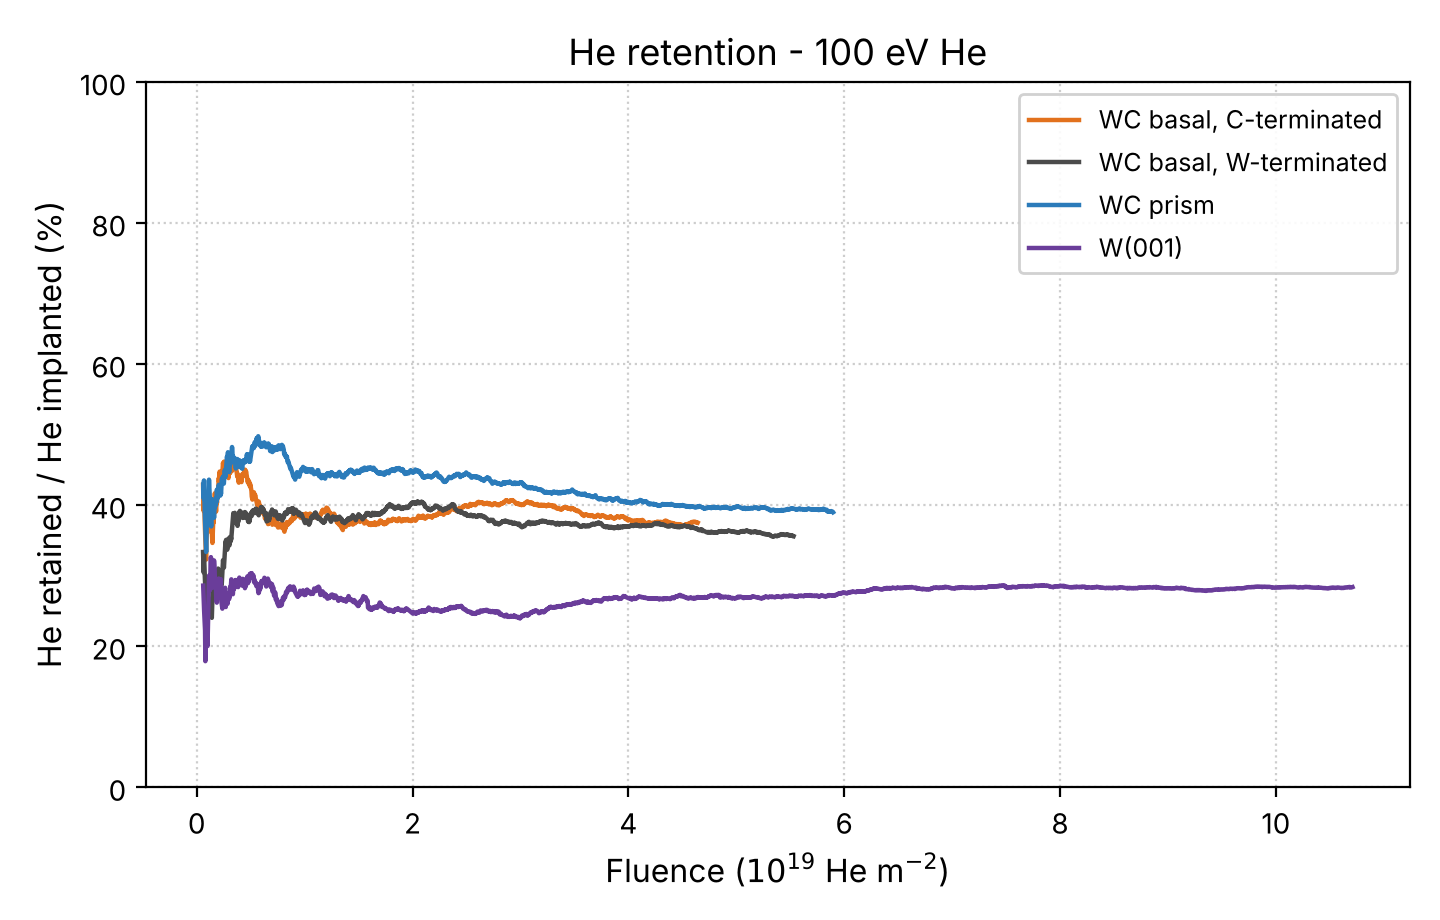

he_clusters_100eV.png


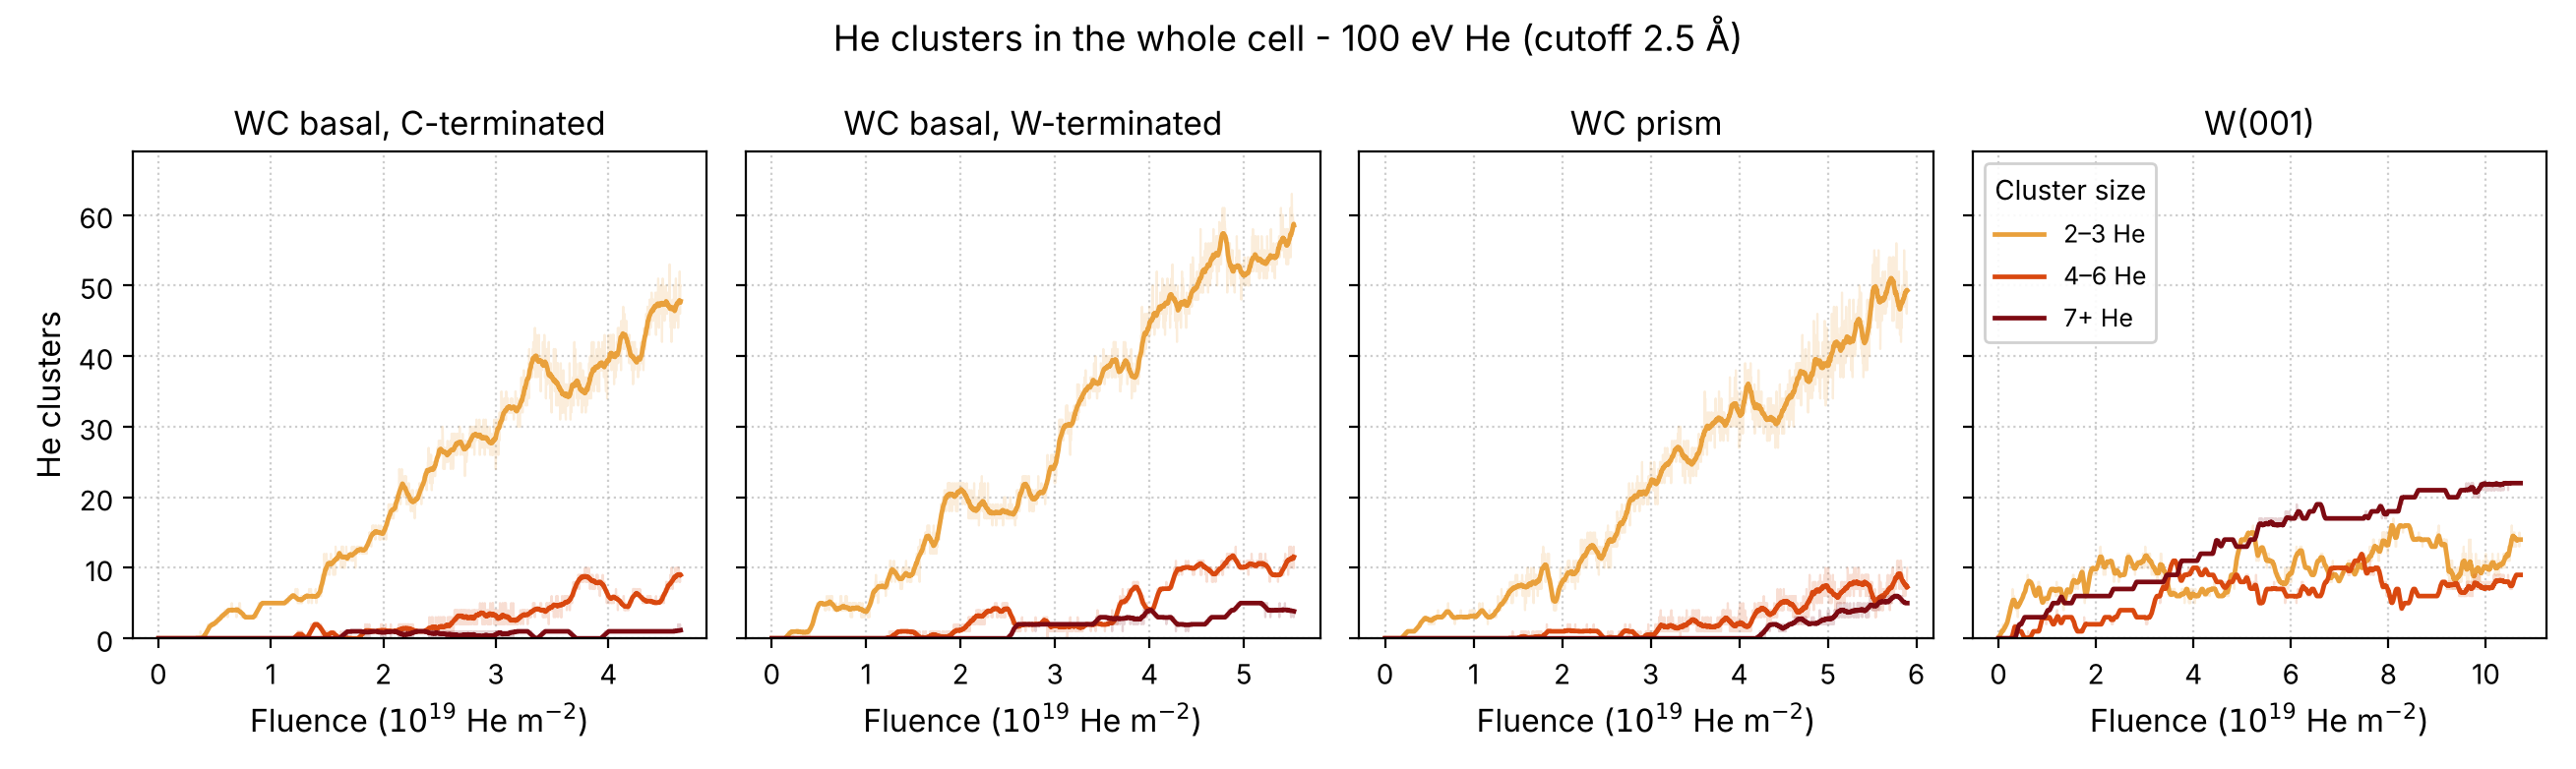

W001_surface_He.png


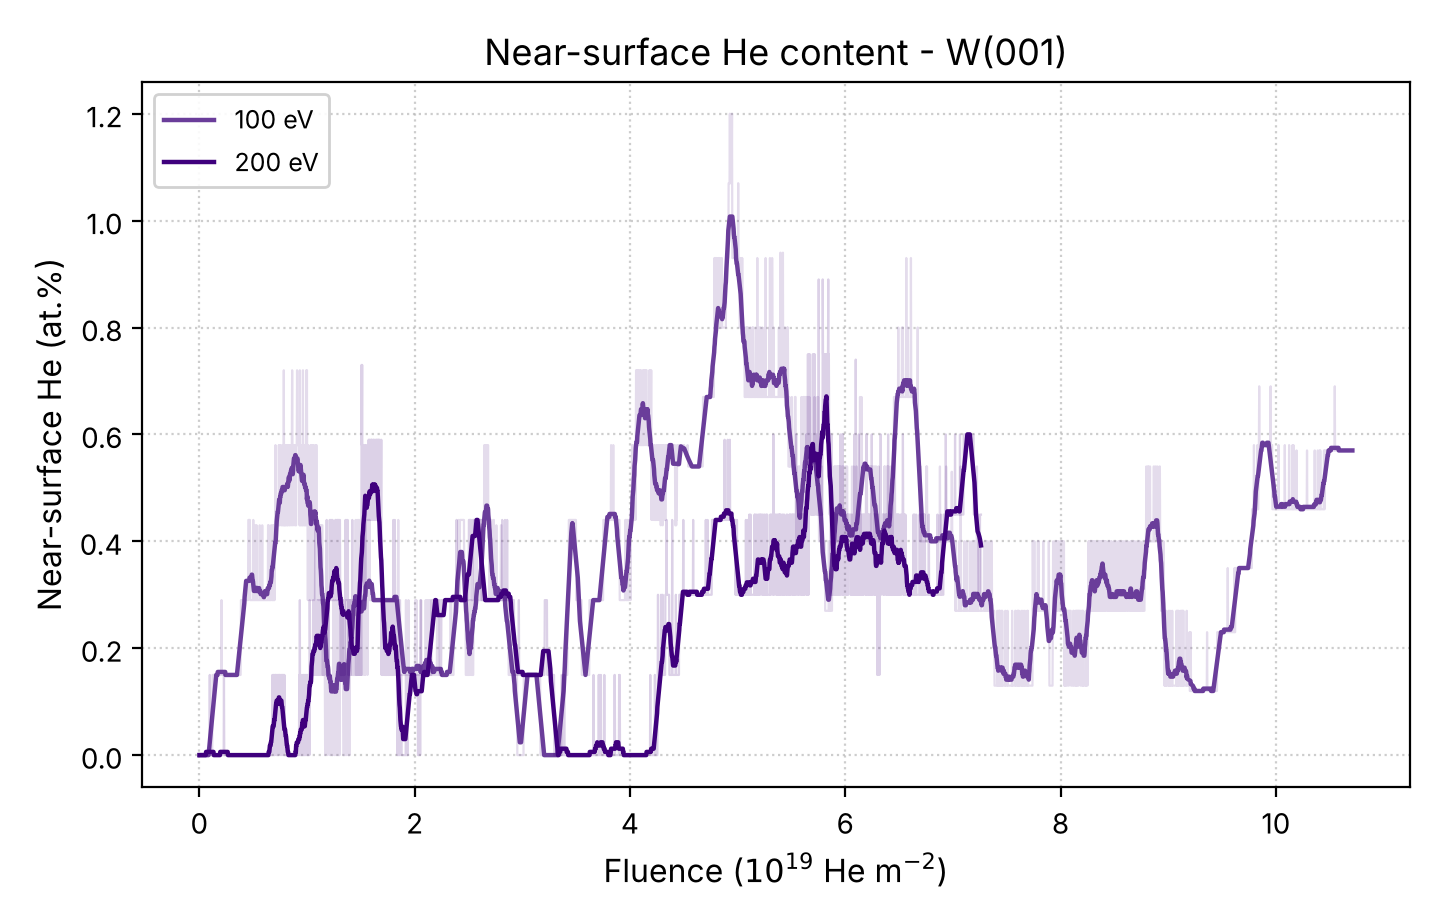

In [11]:
show(NB_OUT, ['surface_W_pct_100eV.png', 'he_retention_100eV.png', 'he_clusters_100eV.png', 'W001_surface_He.png'])